# Oil-price changes and inflation: US, China, Japan and Canada
Monthly 2000-2024, separate country models with the same three substantive variables: prior Brent
change T, monthly CPI inflation Y, prior global activity C. Candidate DAG: C -> T -> Y and C -> Y.
This is an assumption-dependent observational analysis, not identification of oil supply shocks.

Every country uses **unadjusted national all-items CPI** with country-specific calendar-month effects.
We do not mix officially adjusted US CPI with unadjusted Asian CPI. Fixed seasonal patterns do not
capture all moving holidays (including Lunar New Year), changing seasonality, taxes or administered prices.
Seasonal parameters are statistical structure, not additional claimed causal confounders; explain this
richer temporal model under the course's three-variable requirement. No pooled independence or country
ranking test is assumed. Sources: [OECD](https://data-explorer.oecd.org/),
[Brent](https://fred.stlouisfed.org/series/MCOILBRENTEU), [IGREA](https://www.dallasfed.org/research/igrea).

Four complete calendars, 300 months each; no imputation or series splicing.
              monthly                                                  yearly                                                       T                                                      C                                                 
                count   mean    std    min    25%    50%    75%    max  count   mean    std    min    25%    50%    75%    max  count  mean    std    min    25%    50%    75%    max  count   mean    std    min    25%    50%    75%    max
country                                                                                                                                                                                                                                      
Canada          300.0  0.182  0.389 -1.037 -0.080  0.187  0.434  1.431  300.0  2.232  1.388 -0.950  1.354  2.082  2.732  8.133  300.0  0.09  1.011 -4.258 -0.462  0.197  0.709  5.985  300.0  0.075  0.681 -1.625 

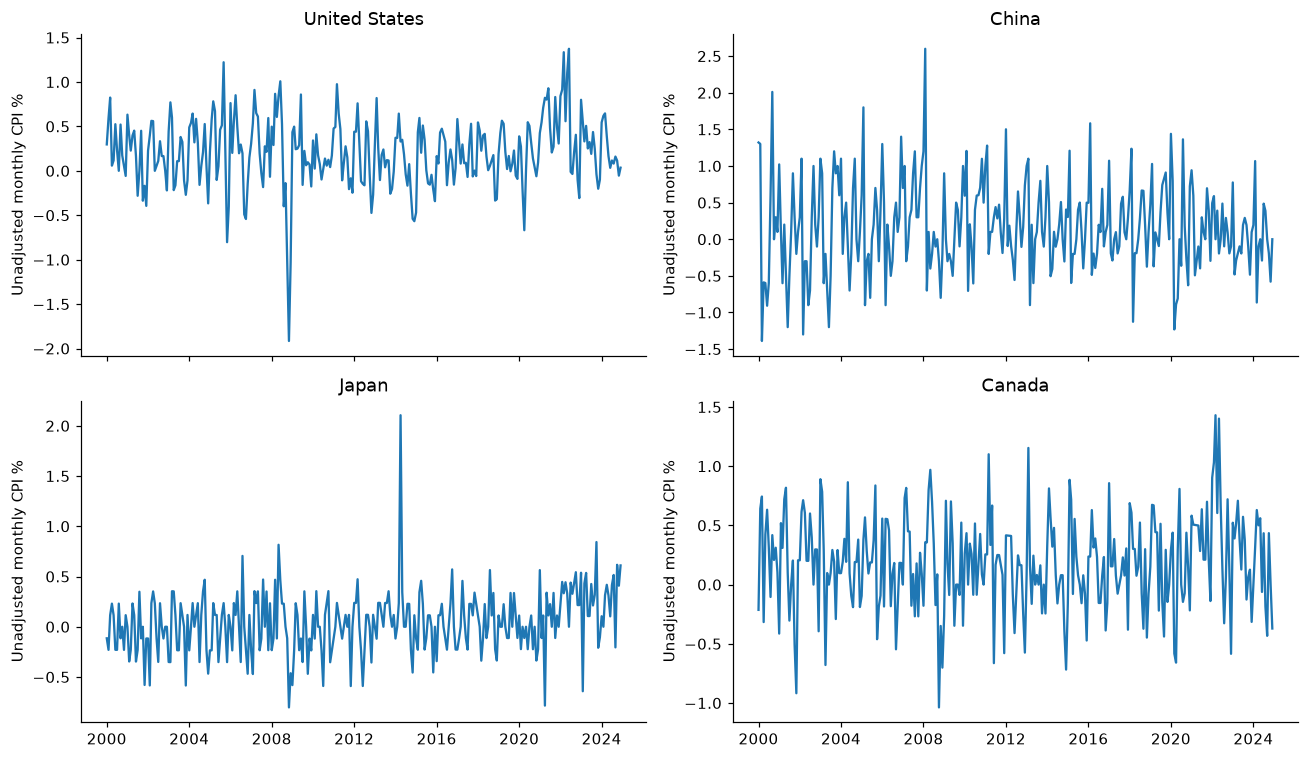

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from analysis.model import SEASON, design, log_target, sample_model, summarize
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
COUNTRIES={'USA':'United States','CHN':'China','JPN':'Japan','CAN':'Canada'}
FLOWS={'USA':'DSD_PRICES@DF_PRICES_ALL','CHN':'DSD_PRICES@DF_PRICES_ALL',
       'JPN':'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL','CAN':'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL'}
plt.rcParams.update({'figure.figsize':(10,4),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def plot_save(name):
    plt.tight_layout();plt.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close()

frames=[]
for manifest_name in ['manifest.json','country_manifest.json']:
    for item in json.loads((ROOT/'data/raw'/manifest_name).read_text()):
        path=ROOT/'data/raw'/item['file']
        assert hashlib.sha256(path.read_bytes()).hexdigest()==item['sha256'],item['file']
        if manifest_name=='country_manifest.json':
            f=pd.read_csv(path);f['flow']=item['flow'];frames.append(f)
cpi=pd.concat(frames,ignore_index=True)
assert not cpi.duplicated(['REF_AREA','flow','ADJUSTMENT','TIME_PERIOD']).any()
oil=pd.read_csv(ROOT/'data/raw/brent_direct.csv',parse_dates=[0]);oil.columns=['date','oil_usd']
dem=pd.read_csv(ROOT/'data/raw/igrea.csv',parse_dates=[0]);dem.columns=['date','global_activity']
assert not oil.date.duplicated().any() and not dem.date.duplicated().any()
base=pd.DataFrame({'date':pd.date_range('1999-01-01','2024-12-01',freq='MS')})
base=base.merge(oil,on='date',how='left',validate='one_to_one').merge(dem,on='date',how='left',validate='one_to_one')
base['oil_pct']=base.oil_usd.pct_change(fill_method=None)*100
base['T']=base.oil_pct.shift(1)/10;base['C']=base.global_activity.shift(2)/100
groups={};panels=[]
for iso,name in COUNTRIES.items():
    f=cpi[(cpi.REF_AREA==iso)&(cpi.flow==FLOWS[iso])&(cpi.ADJUSTMENT=='N')].copy()
    assert f.FREQ.eq('M').all() and f.UNIT_MEASURE.eq('IX').all() and f.MEASURE.eq('CPI').all()
    f['date']=pd.to_datetime(f.TIME_PERIOD)
    d=base.merge(f[['date','OBS_VALUE']].rename(columns={'OBS_VALUE':'cpi'}),on='date',how='left',validate='one_to_one')
    d['monthly']=d.cpi.pct_change(fill_method=None)*100;d['yearly']=d.cpi.pct_change(12,fill_method=None)*100
    d['last_monthly']=d.monthly.shift(1);d['last_year_same_month']=d.monthly.shift(12)
    d['month']=d.date.dt.month;d['country']=name;d['iso3']=iso;d['adjustment']='N';d['flow']=FLOWS[iso]
    d=d[d.date.ge('2000-01-01')].reset_index(drop=True)
    assert len(d)==300 and d[['monthly','yearly','T','C','last_monthly']].notna().all().all()
    groups[iso]=d;panels.append(d)
panel=pd.concat(panels,ignore_index=True)
assert len(panel)==1200 and not panel.duplicated(['iso3','date']).any()
panel.to_csv(ROOT/'data/processed/multicountry_monthly.csv',index=False)
description=panel.groupby('country')[['monthly','yearly','T','C']].describe()
description.to_csv(OUT/'descriptive_statistics.csv')
print('Four complete calendars, 300 months each; no imputation or series splicing.')
print(description.round(3).to_string())
print('Shared treatment-demand correlation:',round(groups['USA']['T'].corr(groups['USA'].C),3))
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ax,(iso,d) in zip(axes.flat,groups.items()):
    ax.plot(d.date,d.monthly);ax.set_title(COUNTRIES[iso]);ax.set_ylabel('Unadjusted monthly CPI %')
plot_save('country_inflation')

## Numerical model implementation

Shared by all four country fits; no pooling of observations.

In [2]:
"""Seasonal Gaussian AR(1) regression and Metropolis-within-Gibbs sampling."""
import numpy as np
import pandas as pd
import arviz as az
from scipy.linalg import helmert, cho_solve, solve_triangular

SEASON = helmert(12, full=False).T

def design(d, adjusted=True):
    columns = [np.ones(len(d)), d['T'].to_numpy()]
    names = ['alpha', 'beta']
    scales = [.5, .3]
    if adjusted:
        columns.append(d['C'].to_numpy())
        names.append('gamma'); scales.append(.5)
    X = np.column_stack(columns + [SEASON[d.month.to_numpy()-1]])
    return X, names + [f'season_{i+1}' for i in range(11)], np.array(scales + [.5]*11)

def log_target(z, X, y, scales):
    p = X.shape[1]; b = z[:p]; ls = z[p]; phi = np.tanh(z[p+1]); sigma = np.exp(ls)
    r = y-X@b
    ss = (1-phi**2)*r[0]**2 + np.sum((r[1:]-phi*r[:-1])**2)
    return (-len(y)*ls + .5*np.log1p(-phi**2) - .5*ss/sigma**2
            - .5*np.sum((b/scales)**2) - .5*(sigma/.5)**2 + ls + np.log1p(-phi**2))

def sample_model(X, y, scales, seed=22, warm=2000, keep=6000):
    """Four chains: exact coefficient Gibbs draws, scalar transformed sigma/phi MH draws.

    Proposal scale adaptation stops after warmup. Priors are independent of sigma.
    The stationary initial observation is included in the likelihood and Gibbs precision.
    """
    p = X.shape[1]; prior_precision = np.diag(1/scales**2)
    first = np.outer(X[0],X[0]); A = X[1:].T@X[1:]
    B = X[1:].T@X[:-1]; D = X[:-1].T@X[:-1]
    h0 = X[0]*y[0]; h1 = X[1:].T@y[1:]
    hcross = X[1:].T@y[:-1] + X[:-1].T@y[1:]; hlag = X[:-1].T@y[:-1]
    initial = np.linalg.lstsq(X,y,rcond=None)[0]; resid = y-X@initial
    phi0 = np.clip(pd.Series(resid).autocorr(),-.8,.8)
    sigma0 = max(np.std(resid[1:]-phi0*resid[:-1]),.03)
    chains = []; acceptance = []
    for chain in range(4):
        rng = np.random.default_rng(seed+chain*100)
        ls = np.log(sigma0)+rng.normal(0,.2); eta = np.arctanh(phi0)+rng.normal(0,.2)
        step = np.array([.08,.15]); block = np.zeros(2); accepted = np.zeros(2); saved = []
        for it in range(warm+keep):
            phi = np.tanh(eta); var = np.exp(2*ls)
            G = (1-phi**2)*first+A-phi*(B+B.T)+phi**2*D
            h = (1-phi**2)*h0+h1-phi*hcross+phi**2*hlag
            L = np.linalg.cholesky(G/var+prior_precision)
            mean = cho_solve((L,True),h/var,check_finite=False)
            b = mean + solve_triangular(L.T,rng.normal(size=p),lower=False,check_finite=False)
            r = y-X@b; rfirst = r[0]**2
            ra = r[1:]@r[1:]; rb = r[1:]@r[:-1]; rc = r[:-1]@r[:-1]
            def conditional(a,e):
                if abs(a)>15 or abs(e)>8:
                    return -np.inf
                ph = np.tanh(e); ss = (1-ph**2)*rfirst+ra-2*ph*rb+ph**2*rc
                return (-len(y)*a+1.5*np.log1p(-ph**2)-.5*ss/np.exp(2*a)
                        -.5*(np.exp(a)/.5)**2+a)
            current = conditional(ls,eta)
            for j in range(2):
                a = ls+step[j]*rng.normal() if j==0 else ls
                e = eta+step[j]*rng.normal() if j==1 else eta
                proposed = conditional(a,e)
                if np.log(rng.uniform())<proposed-current:
                    ls,eta,current = a,e,proposed; block[j]+=1
                    if it>=warm:
                        accepted[j]+=1
            if it<warm and (it+1)%100==0:
                step *= np.exp(np.clip(block/100-.44,-.2,.2)); block[:]=0
            if it>=warm:
                saved.append(np.r_[b,np.exp(ls),np.tanh(eta)])
        chains.append(saved); acceptance.append(accepted/keep)
    return np.asarray(chains), np.asarray(acceptance)

def summarize(chains,names):
    names = names + ['sigma','phi']
    posterior = {name:chains[:,:,j] for j,name in enumerate(names)}
    table = az.summary(az.from_dict(posterior=posterior),hdi_prob=.95,round_to=6)
    table = table.rename_axis('parameter').reset_index()
    table['lower95'] = np.quantile(chains,.025,axis=(0,1))
    table['upper95'] = np.quantile(chains,.975,axis=(0,1))
    table['sampling_pass'] = (table.r_hat<1.01)&(table.ess_bulk>400)&(table.ess_tail>400)
    return table


## Same estimand, priors and seasonal structure in each country
T = oil percentage change in month t-1 / 10; Y = unadjusted monthly CPI inflation in t;
C = IGREA in t-2 / 100. Beta is monthly inflation percentage points per 10-percentage-point oil change.

Y_t = alpha + beta*T_t + gamma*C_t + s_month(t) + u_t; u_t = phi*u_(t-1) + epsilon_t.
epsilon ~ Normal(0,sigma^2); initial u_0 ~ Normal(0,sigma^2/(1-phi^2)); |phi|<1.
Eleven orthonormal Helmert contrasts give seasonal effects summing to zero. Both adjusted and unadjusted
models retain seasonality; the unadjusted comparison omits C only. Independent working priors:
alpha~N(0,.5^2), beta~N(0,.3^2), gamma~N(0,.5^2), each seasonal contrast~N(0,.5^2),
sigma~HalfNormal(.5), phi~Uniform(-1,1). Prior scale justification is provisional, not completed by a
predictive check alone. All countries use the same priors; no tuning for significant coefficients.

Four Metropolis-within-Gibbs chains: exact Gaussian coefficient draws, transformed sigma/phi proposals
with Jacobians; 2,000 warmup then 6,000 retained iterations per chain. Adaptation stops after warmup.
The numerical implementation is in analysis/model.py and is included in the generated notebook.

All four AR likelihoods/Jacobians agree with independent covariance calculations.


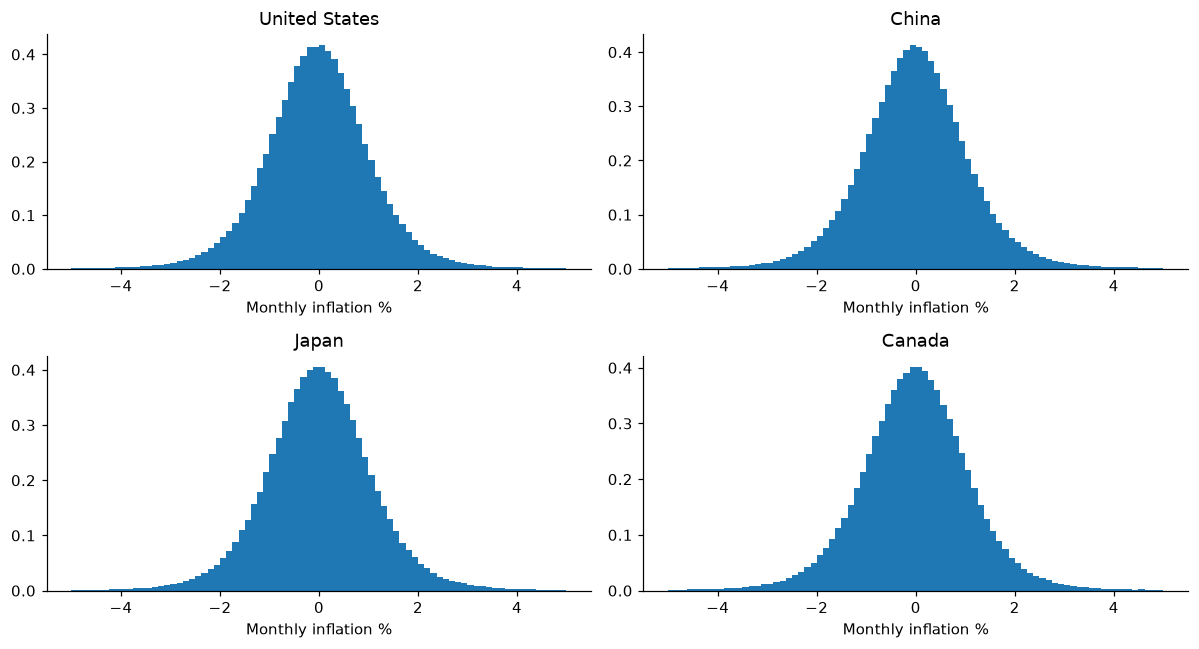

In [3]:
assert np.allclose(SEASON.sum(axis=0),0) and np.allclose(SEASON.T@SEASON,np.eye(11))
for iso,d in groups.items():
    X,names,scales=design(d);X=X[:12];y=d.monthly.to_numpy()[:12];p=X.shape[1]
    def independent(z):
        sig=np.exp(z[p]);ph=np.tanh(z[p+1]);i=np.arange(len(y))
        cov=sig**2/(1-ph**2)*ph**np.abs(i[:,None]-i[None,:])
        return (multivariate_normal.logpdf(y,mean=X@z[:p],cov=cov)-.5*np.sum((z[:p]/scales)**2)
                -.5*(sig/.5)**2+z[p]+np.log1p(-ph**2))
    z1=np.r_[np.zeros(p),np.log(.25),np.arctanh(.3)];z2=np.r_[np.ones(p)*.03,np.log(.4),np.arctanh(-.2)]
    assert np.isclose(log_target(z1,X,y,scales)-log_target(z2,X,y,scales),independent(z1)-independent(z2),atol=1e-8)
print('All four AR likelihoods/Jacobians agree with independent covariance calculations.')
rng=np.random.default_rng(50);prior_rows=[];fig,axes=plt.subplots(2,2,figsize=(11,6))
for ax,(iso,d) in zip(axes.flat,groups.items()):
    X,names,scales=design(d);count=1500;b=rng.normal(size=(count,len(names)))*scales
    sig=np.abs(rng.normal(0,.5,count));ph=rng.uniform(-1,1,count);res=np.empty((count,len(d)))
    res[:,0]=rng.normal(size=count)*sig/np.sqrt(1-ph**2)
    for t in range(1,len(d)):res[:,t]=ph*res[:,t-1]+rng.normal(size=count)*sig
    yp=b@X.T+res;lo,hi=np.quantile(yp,[.025,.975]);prior_rows.append({'iso3':iso,'lower95':lo,'upper95':hi})
    ax.hist(yp.ravel(),bins=80,range=(-5,5),density=True);ax.set_title(COUNTRIES[iso]);ax.set_xlabel('Monthly inflation %')
plot_save('prior_predictive');pd.DataFrame(prior_rows).to_csv(OUT/'prior_predictive.csv',index=False)

## Country fits and matched confounder comparisons
ArviZ rank R-hat, bulk/tail ESS, MCSE and traces assess computation. A failed diagnostic is flagged.
Conditional country intervals are not formal country-difference tests: countries share shocks and errors.

USA unadjusted beta 0.0939 sampling pass True


USA adjusted beta 0.0948 sampling pass True


CHN unadjusted beta 0.0872 sampling pass True


CHN adjusted beta 0.0837 sampling pass True


JPN unadjusted beta 0.0353 sampling pass True


JPN adjusted beta 0.0348 sampling pass True


CAN unadjusted beta 0.1192 sampling pass True


CAN adjusted beta 0.118 sampling pass True


      country iso3      model   beta  lower95  upper95  sampling_pass
United States  USA unadjusted 0.0939   0.0591   0.1304           True
United States  USA   adjusted 0.0948   0.0596   0.1309           True
        China  CHN unadjusted 0.0872   0.0382   0.1360           True
        China  CHN   adjusted 0.0837   0.0358   0.1321           True
        Japan  JPN unadjusted 0.0353   0.0041   0.0667           True
        Japan  JPN   adjusted 0.0348   0.0041   0.0655           True
       Canada  CAN unadjusted 0.1192   0.0816   0.1564           True
       Canada  CAN   adjusted 0.1180   0.0804   0.1551           True


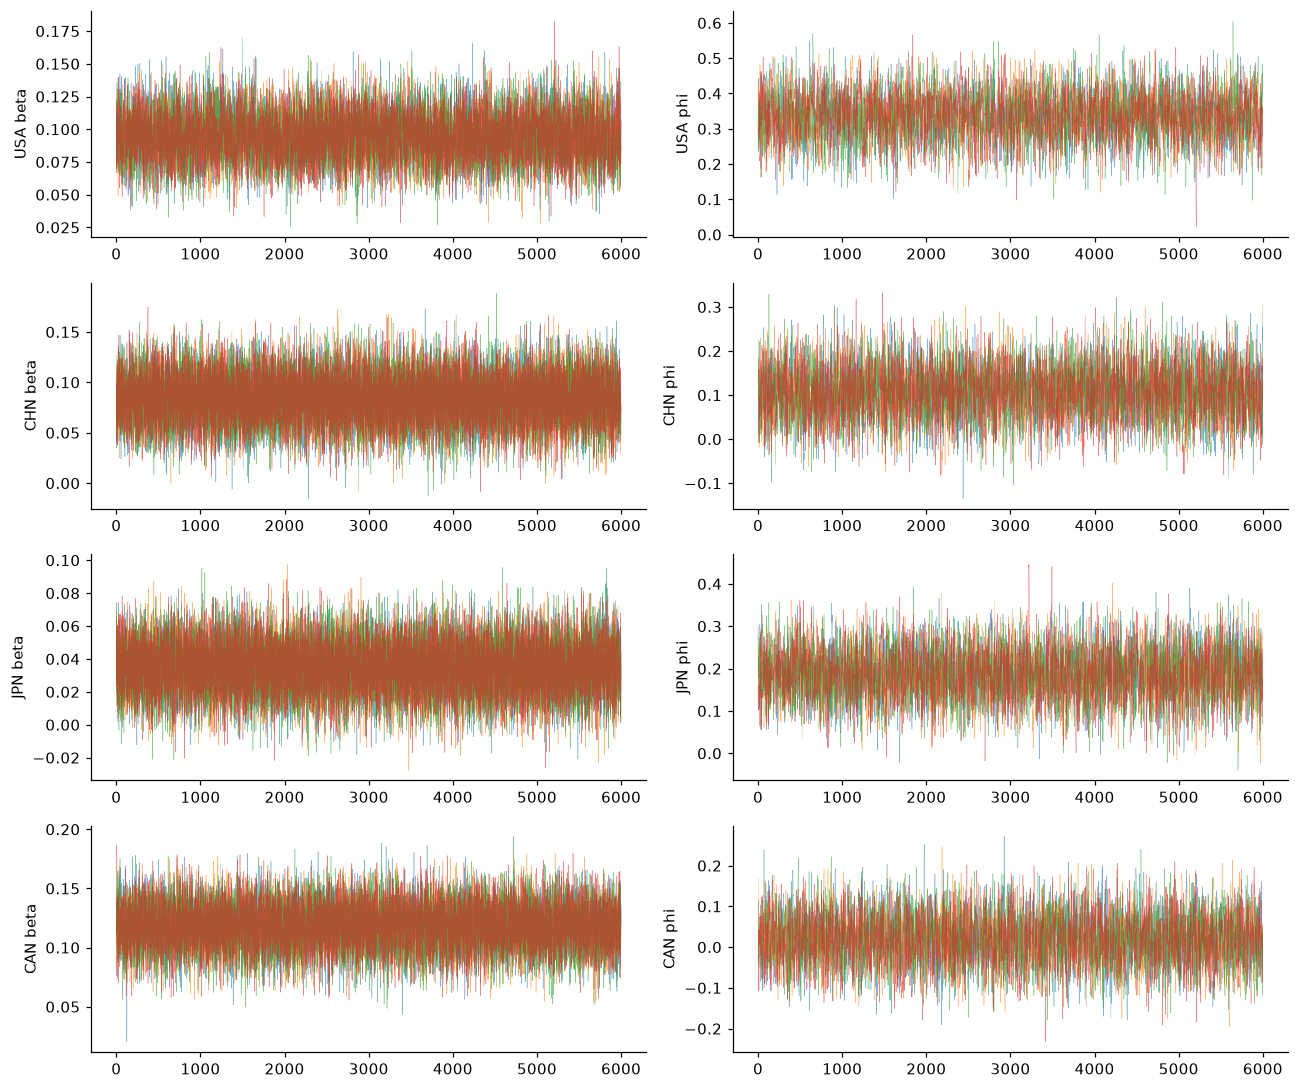

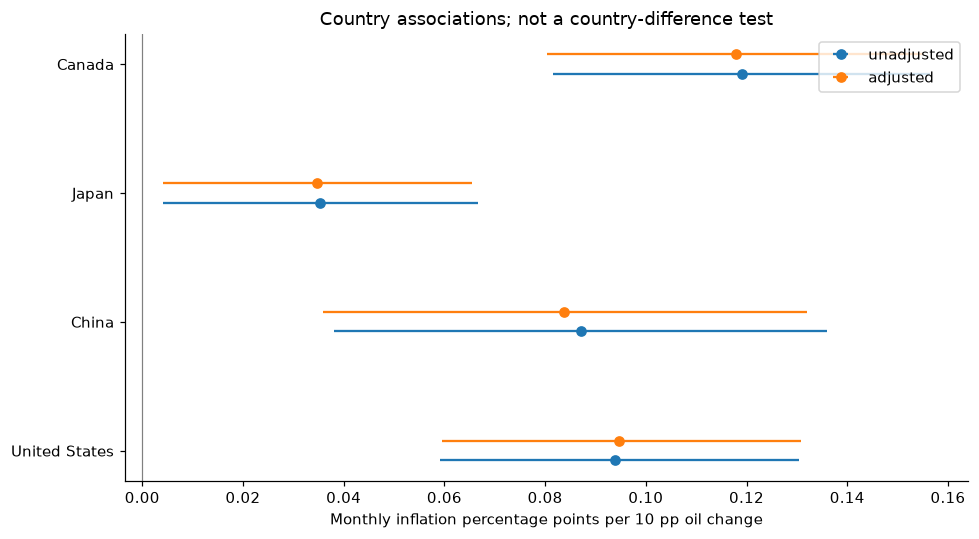

In [4]:
fits={};tables=[];coefficient_rows=[];acceptance_rows=[]
for i,(iso,d) in enumerate(groups.items()):
    fits[iso]={}
    for adjusted in [False,True]:
        label='adjusted' if adjusted else 'unadjusted';X,names,scales=design(d,adjusted)
        chains,accept=sample_model(X,d.monthly.to_numpy(),scales,seed=22+i*1000+int(adjusted)*50)
        fits[iso][label]=chains;table=summarize(chains,names);table.insert(0,'model',label);table.insert(0,'iso3',iso);tables.append(table)
        beta=table[table.parameter.eq('beta')].iloc[0]
        coefficient_rows.append({'country':COUNTRIES[iso],'iso3':iso,'model':label,'beta':beta['mean'],
                                 'lower95':beta.lower95,'upper95':beta.upper95,'sampling_pass':bool(table.sampling_pass.all())})
        for c,rates in enumerate(accept):acceptance_rows.append({'iso3':iso,'model':label,'chain':c+1,'sigma_accept':rates[0],'phi_accept':rates[1]})
        print(iso,label,'beta',round(beta['mean'],4),'sampling pass',bool(table.sampling_pass.all()),flush=True)
diagnostics=pd.concat(tables,ignore_index=True);coefficients=pd.DataFrame(coefficient_rows)
diagnostics.to_csv(OUT/'posterior_diagnostics.csv',index=False);coefficients.to_csv(OUT/'country_coefficients.csv',index=False)
pd.DataFrame(acceptance_rows).to_csv(OUT/'sampler_acceptance.csv',index=False)
np.savez_compressed(OUT/'posterior_draws.npz',**{iso+'_'+label:a for iso,f in fits.items() for label,a in f.items()})
print(coefficients.round(4).to_string(index=False))
fig,axes=plt.subplots(4,2,figsize=(12,10))
for row,(iso,f) in enumerate(fits.items()):
    for c in range(4):
        axes[row,0].plot(f['adjusted'][c,:,1],lw=.3,alpha=.6);axes[row,1].plot(f['adjusted'][c,:,-1],lw=.3,alpha=.6)
    axes[row,0].set_ylabel(iso+' beta');axes[row,1].set_ylabel(iso+' phi')
plot_save('mcmc_traces')
fig,ax=plt.subplots(figsize=(9,5))
for j,label in enumerate(['unadjusted','adjusted']):
    q=coefficients[coefficients.model.eq(label)].set_index('iso3').loc[list(COUNTRIES)]
    ax.errorbar(q.beta,np.arange(4)+(j-.5)*.15,xerr=np.array([q.beta-q.lower95,q.upper95-q.beta]),fmt='o',label=label)
ax.set_yticks(np.arange(4),list(COUNTRIES.values()));ax.axvline(0,color='grey',lw=.8);ax.legend()
ax.set_xlabel('Monthly inflation percentage points per 10 pp oil change');ax.set_title('Country associations; not a country-difference test')
plot_save('country_coefficients')

## Separate simulation validation: seasonality, confounding and dependent errors
True beta=.15, gamma=.25, sigma=.15, phi=.4. Synthetic observations never enter real-data fits.
Recovery validates computation under known conditions, not the real-world DAG.

In [5]:
rng=np.random.default_rng(81);simdata=groups['USA'][['date','month']].copy();N=len(simdata);C=np.zeros(N)
for i in range(1,N):C[i]=.6*C[i-1]+rng.normal(0,.5)
simdata['C']=C;simdata['T']=.8*C+rng.normal(0,.7,N);Xs,names,scales=design(simdata)
truth=np.r_[.2,.15,.25,np.linspace(-.15,.15,11)];u=np.empty(N);u[0]=rng.normal(0,.15/np.sqrt(1-.4**2))
for i in range(1,N):u[i]=.4*u[i-1]+rng.normal(0,.15)
ys=Xs@truth+u;simulation=[]
for adjusted in [False,True]:
    X,names,scales=design(simdata,adjusted);chain,accept=sample_model(X,ys,scales,seed=171+int(adjusted)*100)
    table=summarize(chain,names);table.insert(0,'model','adjusted' if adjusted else 'unadjusted')
    if adjusted:
        table['truth']=np.r_[truth,.15,.4];table['truth_in_interval']=(table.truth>=table.lower95)&(table.truth<=table.upper95)
    simulation.append(table)
simulation=pd.concat(simulation,ignore_index=True);simulation.to_csv(OUT/'simulation_recovery.csv',index=False)
print(simulation[simulation.parameter.isin(['beta','gamma','sigma','phi'])].round(4).to_string(index=False))

     model parameter   mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd   ess_bulk   ess_tail  r_hat  lower95  upper95  sampling_pass  truth truth_in_interval
unadjusted      beta 0.1986 0.0128    0.1735     0.2235     0.0001   0.0001 17849.8233 21242.3056 1.0001   0.1738   0.2239           True    NaN               NaN
unadjusted     sigma 0.1885 0.0080    0.1736     0.2045     0.0001   0.0001  5142.4622  5186.7426 1.0004   0.1739   0.2050           True    NaN               NaN
unadjusted       phi 0.4915 0.0538    0.3877     0.5997     0.0008   0.0006  4573.0910  5305.3530 1.0005   0.3861   0.5984           True    NaN               NaN
  adjusted      beta 0.1503 0.0109    0.1294     0.1724     0.0001   0.0000 23867.5004 23489.4932 1.0001   0.1289   0.1720           True   0.15              True
  adjusted     gamma 0.2398 0.0188    0.2030     0.2761     0.0001   0.0001 23863.3963 24139.6420 1.0001   0.2030   0.2761           True   0.25              True
  adjusted     sigma 0

## Posterior prediction, residual checks and robustness for every country
Pointwise predictive intervals include seasonal mean uncertainty and dependent residuals. Plug-in
innovation tests and extremes expose misspecification; satisfactory sampling is not model validation.
HAC sensitivity regressions retain calendar effects and are not identical to Bayesian AR estimates.

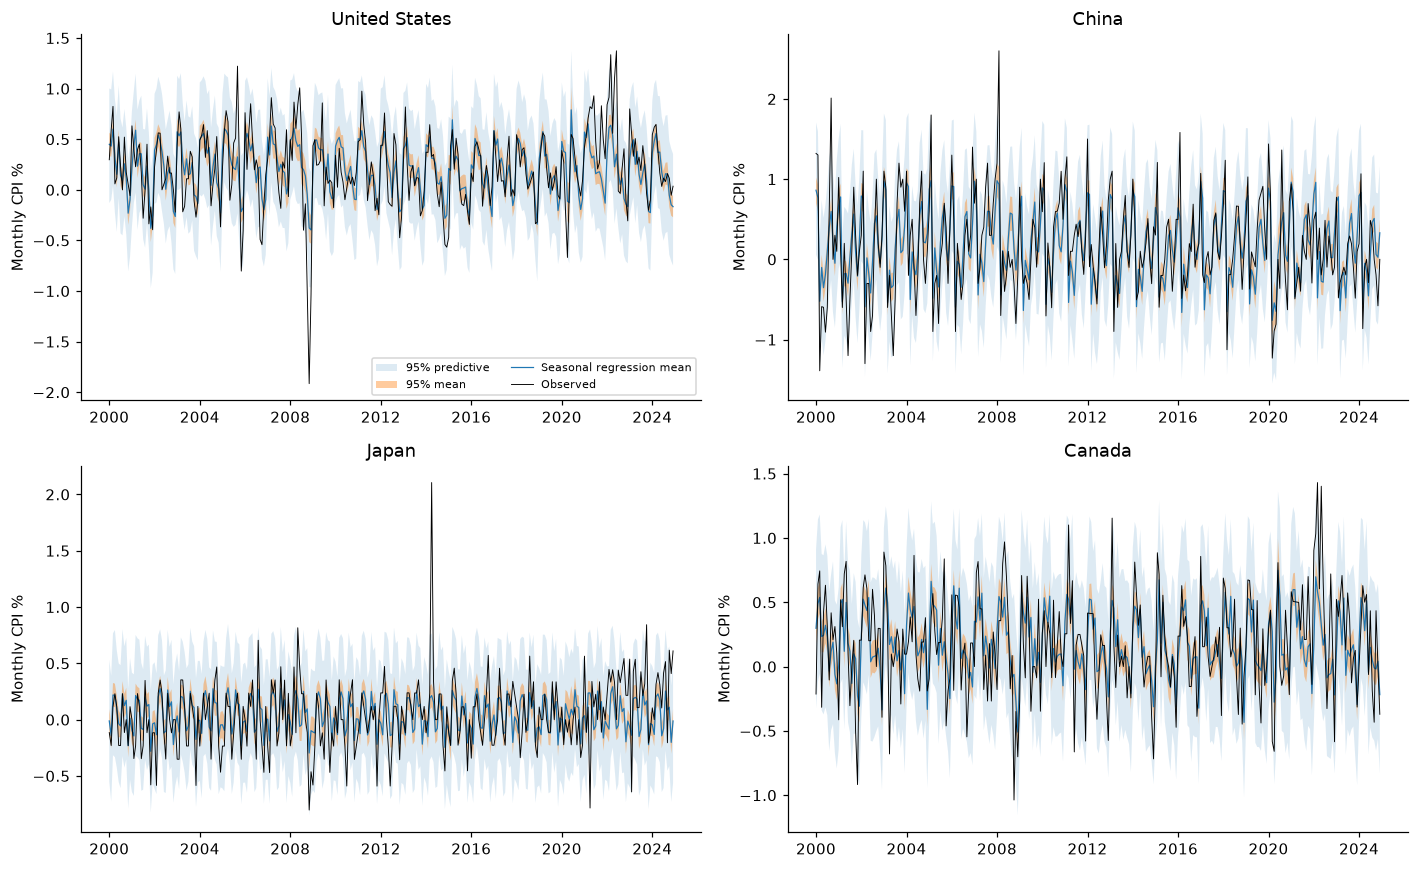

 lag  lb_stat  lb_pvalue iso3
   6   3.3809     0.7597  USA
  12  20.8328     0.0529  USA
   6   3.1406     0.7910  CHN
  12  24.6234     0.0167  CHN
   6   7.3539     0.2894  JPN
  12  27.2268     0.0072  JPN
   6  10.5685     0.1027  CAN
  12  16.5823     0.1660  CAN


In [6]:
predictive=[];innovations=[];robustness=[];prior_sensitivity=[];season_rows=[];fig,axes=plt.subplots(2,2,figsize=(13,8))
for i,(ax,(iso,d)) in enumerate(zip(axes.flat,groups.items())):
    X,names,scales=design(d);flat=fits[iso]['adjusted'].reshape(-1,len(names)+2)
    rng=np.random.default_rng(70+i);draw=flat[rng.choice(len(flat),1500,replace=False)];mu=draw[:,:len(names)]@X.T;r=np.empty_like(mu)
    r[:,0]=rng.normal(size=len(draw))*draw[:,-2]/np.sqrt(1-draw[:,-1]**2)
    for t in range(1,len(d)):r[:,t]=draw[:,-1]*r[:,t-1]+rng.normal(size=len(draw))*draw[:,-2]
    rep=mu+r;mean=flat.mean(axis=0);res=d.monthly.to_numpy()-X@mean[:-2];innov=res[1:]-mean[-1]*res[:-1]
    lb=acorr_ljungbox(innov,lags=[6,12],return_df=True).rename_axis('lag').reset_index();lb['iso3']=iso;innovations.append(lb)
    for name,fun in [('lag1',lambda a:pd.Series(a).autocorr()),('maximum',np.max),('minimum',np.min),('std',np.std)]:
        v=np.array([fun(a) for a in rep]);obs=fun(d.monthly.to_numpy());lo,hi=np.quantile(v,[.025,.975])
        predictive.append({'iso3':iso,'statistic':name,'observed':obs,'rep_lower95':lo,'rep_upper95':hi,'fraction_rep_ge_observed':np.mean(v>=obs)})
    ax.fill_between(d.date,*np.quantile(rep,[.025,.975],axis=0),alpha=.15,label='95% predictive')
    ax.fill_between(d.date,*np.quantile(mu,[.025,.975],axis=0),alpha=.4,label='95% mean')
    ax.plot(d.date,mu.mean(axis=0),lw=.8,label='Seasonal regression mean');ax.plot(d.date,d.monthly,color='black',lw=.6,label='Observed')
    ax.set_title(COUNTRIES[iso]);ax.set_ylabel('Monthly CPI %')
    for month in range(1,13):
        s=flat[:,3:14]@SEASON[month-1];season_rows.append({'iso3':iso,'month':month,'mean':s.mean(),'lower95':np.quantile(s,.025),'upper95':np.quantile(s,.975)})
    for label,g in [('all',d),('2000-2019',d[d.date<'2020-01-01']),('2020-2024',d[d.date>='2020-01-01']),('exclude 2020-2022',d[~d.date.dt.year.between(2020,2022)]),('exclude oil changes >30%',d[d['T'].abs()<=3])]:
        fit=sm.OLS(g.monthly,design(g)[0]).fit(cov_type='HAC',cov_kwds={'maxlags':12});ci=np.asarray(fit.conf_int())[1]
        robustness.append({'iso3':iso,'sample':label,'n':len(g),'beta':np.asarray(fit.params)[1],'HAC_low':ci[0],'HAC_high':ci[1]})
    for scale in [.15,.3,.6]:
        lw=-.5*(flat[:,1]/scale)**2+.5*(flat[:,1]/.3)**2;w=np.exp(lw-lw.max());w/=w.sum();idx=np.argsort(flat[:,1])
        q=np.interp([.025,.975],np.cumsum(w[idx]),flat[idx,1]);prior_sensitivity.append({'iso3':iso,'beta_prior_sd':scale,'beta_mean':w@flat[:,1],'lower95':q[0],'upper95':q[1],'importance_ESS':1/(w@w)})
axes[0,0].legend(fontsize=7,ncol=2);plot_save('posterior_predictive')
pd.DataFrame(predictive).to_csv(OUT/'predictive_checks.csv',index=False)
pd.concat(innovations,ignore_index=True).to_csv(OUT/'innovation_ljung_box.csv',index=False)
pd.DataFrame(robustness).to_csv(OUT/'robustness.csv',index=False)
pd.DataFrame(prior_sensitivity).to_csv(OUT/'prior_sensitivity.csv',index=False)
pd.DataFrame(season_rows).to_csv(OUT/'seasonal_effects.csv',index=False)
print(pd.concat(innovations,ignore_index=True).round(4).to_string(index=False))

## Country-specific chronological predictions
Train once on 2000-2019, evaluate one-step predictions over 2020-2024 using observed previous residuals.
Seasonal coefficients are trained on training data only. Compare persistence, training calendar-month
means and last year's same-month inflation. Sources are revised; release delays are not reconstructed.
This is an exploratory retrospective comparison, not an untouched real-time forecasting experiment.

Completed training/holdout: USA


Completed training/holdout: CHN


Completed training/holdout: JPN


Completed training/holdout: CAN


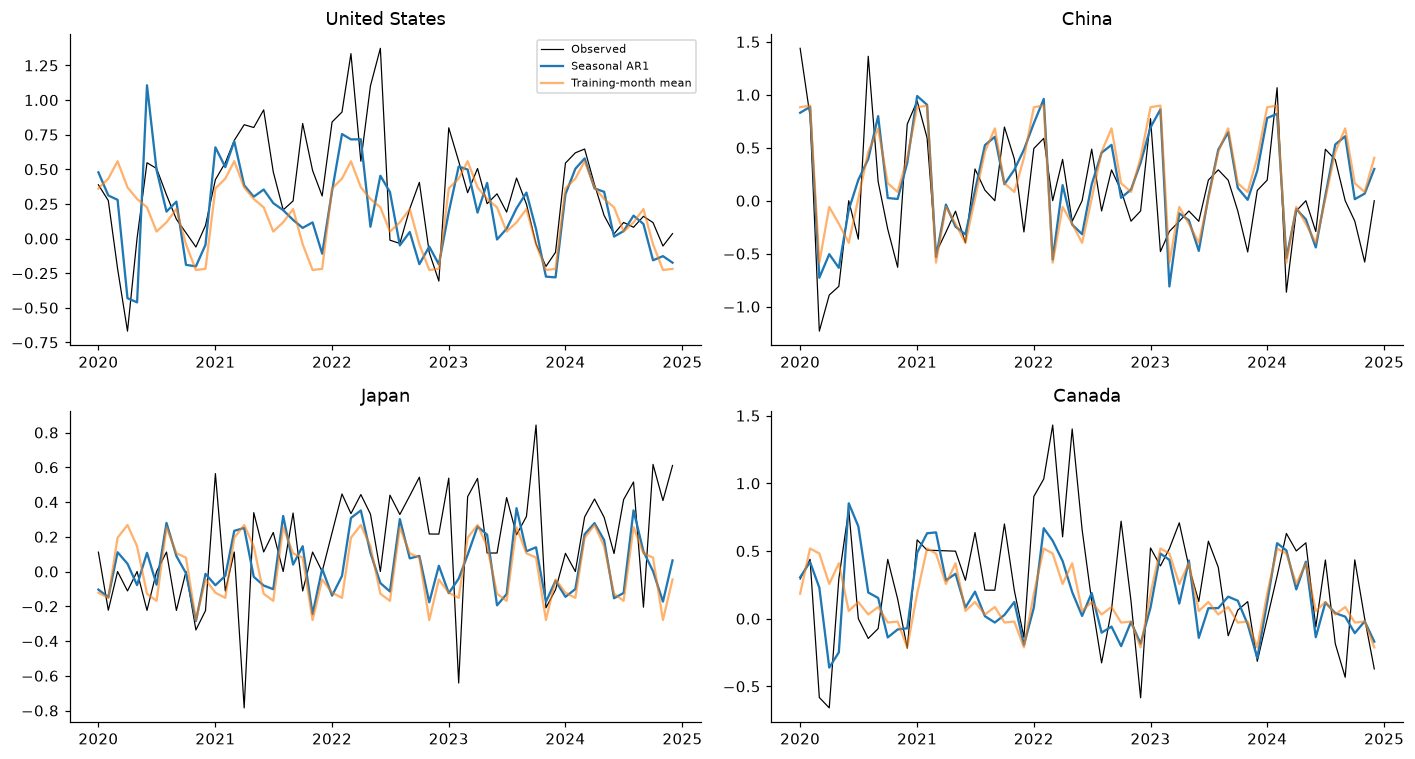

iso3                                model  train_n  test_n    MAE   RMSE
 USA                        training mean      240      60 0.3236 0.4231
 USA                 last-month inflation      240      60 0.2749 0.3765
 USA         training calendar-month mean      240      60 0.2765 0.3883
 USA                 same month last year      240      60 0.3604 0.4812
 USA       Bayesian seasonal adjusted AR1      240      60 0.2464 0.3369
 USA seasonal adjusted independent errors      240      60 0.2684 0.3634
 CHN                        training mean      240      60 0.4325 0.5412
 CHN                 last-month inflation      240      60 0.5235 0.6967
 CHN         training calendar-month mean      240      60 0.3804 0.4572
 CHN                 same month last year      240      60 0.4852 0.6037
 CHN       Bayesian seasonal adjusted AR1      240      60 0.3409 0.4216
 CHN seasonal adjusted independent errors      240      60 0.3433 0.4244
 JPN                        training mean      240 

In [7]:
metrics=[];training=[];orders=[];fig,axes=plt.subplots(2,2,figsize=(13,7))
for i,(ax,(iso,d)) in enumerate(zip(axes.flat,groups.items())):
    train=d[d.date<'2020-01-01'];test=d[d.date>='2020-01-01'];X,names,scales=design(train)
    chain,accept=sample_model(X,train.monthly.to_numpy(),scales,seed=122+i*1000)
    dt=summarize(chain,names);dt['iso3']=iso;training.append(dt);bt=chain.mean(axis=(0,1))
    allmu=design(d)[0]@bt[:-2];allr=d.monthly.to_numpy()-allmu;conditional=allmu[240:]+bt[-1]*allr[239:-1]
    preds={'training mean':np.repeat(train.monthly.mean(),len(test)),'last-month inflation':test.last_monthly.to_numpy(),
           'training calendar-month mean':test.month.map(train.groupby('month').monthly.mean()).to_numpy(),
           'same month last year':test.last_year_same_month.to_numpy(),'Bayesian seasonal adjusted AR1':conditional,
           'seasonal adjusted independent errors':design(test)[0]@np.asarray(sm.OLS(train.monthly,X).fit().params)}
    for label,pred in preds.items():
        err=test.monthly.to_numpy()-pred;metrics.append({'iso3':iso,'model':label,'train_n':len(train),'test_n':len(test),'MAE':np.abs(err).mean(),'RMSE':np.sqrt(np.mean(err**2))})
    ax.plot(test.date,test.monthly,color='black',lw=.8,label='Observed');ax.plot(test.date,conditional,label='Seasonal AR1')
    ax.plot(test.date,preds['training calendar-month mean'],alpha=.6,label='Training-month mean');ax.set_title(COUNTRIES[iso])
    for order in [1,2,3]:
        fit=SARIMAX(d.monthly,exog=design(d)[0],trend='n',order=(order,0,0)).fit(disp=False,maxiter=200)
        orders.append({'iso3':iso,'AR_order':order,'AIC':fit.aic,'beta':np.asarray(fit.params)[1],
                       'optimizer_converged':bool(fit.mle_retvals.get('converged',False)),
                       'innovation_LB_p12':acorr_ljungbox(fit.resid,lags=[12],return_df=True).lb_pvalue.iloc[0]})
    print('Completed training/holdout:',iso,flush=True)
axes[0,0].legend(fontsize=7);plot_save('holdout_predictions')
metrics=pd.DataFrame(metrics);metrics.to_csv(OUT/'holdout_metrics.csv',index=False)
training=pd.concat(training,ignore_index=True);training.to_csv(OUT/'training_diagnostics.csv',index=False)
pd.DataFrame(orders).to_csv(OUT/'AR_order_sensitivity.csv',index=False)
print(metrics.round(4).to_string(index=False))

## Interpretation and remaining work
Read coefficients, sampling diagnostics and predictive checks together. Country intervals are conditional
associations, not proof of causal oil effects or country differences. National CPI baskets, exchange
rates, subsidies, policy regimes, omitted demand paths and shared shocks limit the interpretation.
Four histories do not create 1,200 independent global shocks. Calendar-month effects may leave moving
holiday and changing-seasonality effects. Gaussian tail and residual failures must remain visible;
a Student-t extension is future work. See [the project plan](../docs/PROJECT_PLAN.md).

In [8]:
failures={'full_data':int((~diagnostics.sampling_pass).sum()),'training':int((~training.sampling_pass).sum()),
          'simulation':int((~simulation.sampling_pass).sum())}
print('Sampling diagnostic failures:',failures)
if any(failures.values()):
    raise RuntimeError('Inspect saved sampling diagnostics before interpreting results.')
print('All chains: R-hat < 1.01, bulk/tail ESS > 400. This validates sampling, not causality.')
(OUT/'FINDINGS.md').write_text('# Four-country model results\n\n```text\n'+coefficients.round(5).to_string(index=False)+'\n```\n\n'
    'Unadjusted monthly CPI with country-specific calendar-month effects, separate Gaussian AR(1) models. '
    'Intervals are conditional associations, not identified causal effects or country-difference tests. '
    'Inspect residual, predictive, robustness and holdout tables for limitations.\n',encoding='utf-8')
lb=pd.read_csv(OUT/'innovation_ljung_box.csv')
pp=pd.read_csv(OUT/'predictive_checks.csv')
with (OUT/'FINDINGS.md').open('a',encoding='utf-8') as report:
    report.write('\n## Model checks\n\nAll full-data, training and simulation sampling checks pass. '
                 'This does not imply adequate residual or tail behavior.\n\n')
    for iso,name in COUNTRIES.items():
        p12=lb[(lb.iso3==iso)&(lb.lag==12)].lb_pvalue.iloc[0]
        extreme=pp[(pp.iso3==iso)&pp.statistic.isin(['minimum','maximum'])]
        misses=extreme[(extreme.observed<extreme.rep_lower95)|(extreme.observed>extreme.rep_upper95)]
        tail=', '.join(misses.statistic) if len(misses) else 'none in these two checks'
        report.write(f'- {name}: 12-lag innovation p={p12:.4f}; extreme-statistic misses: {tail}.\n')
    report.write('\n## Retrospective holdout RMSE, 2020–2024\n\n')
    for iso,name in COUNTRIES.items():
        m=metrics[metrics.iso3.eq(iso)]
        model=m[m.model.eq('Bayesian seasonal adjusted AR1')].RMSE.iloc[0]
        simple=m[m.model.isin(['training mean','last-month inflation','training calendar-month mean','same month last year'])].sort_values('RMSE').iloc[0]
        report.write(f'- {name}: seasonal demand-adjusted AR1 {model:.4f}; best simple benchmark '
                     f'{simple.RMSE:.4f} ({simple.model}).\n')
    report.write('\nThese are exploratory one-step predictions from revised data with training-only '
                 'seasonal coefficients. They are not real-time vintage forecasts or a controlled '
                 'test of oil information alone: the benchmarks differ in more than the oil predictor. '
                 'No no-oil AR counterfactual forecast model or joint country-difference test is fitted. '
                 'Gaussian model failures and imperfect demand adjustment remain. Student-t errors '
                 'and moving-holiday treatment are future work.\n')

Sampling diagnostic failures: {'full_data': 0, 'training': 0, 'simulation': 0}
All chains: R-hat < 1.01, bulk/tail ESS > 400. This validates sampling, not causality.
